# Notebook 06: Pruebas de Inferencia End-to-End

## Contexto y Validación
Validación integral del pipeline completo de **ClaimVision-AI** simulando una petición real de producción:
1. Ingesta de imagen cruda.
2. Inferencia en el clasificador Keras (score de daño global).
3. Inferencia en el detector PyTorch (bounding boxes de autopartes dañadas).
4. Ensamblado del JSON consolidado y visualización gráfica de las detecciones.


In [3]:
from tensorflow.keras.models import load_model
import config
import pandas as pd
import keras
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import json
import torch
from torch.utils.data import DataLoader
import torchvision
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torch.optim import SGD
from pipeline.preprocessing.cocoDataloader import COCODataset
from torchvision import transforms
from PIL import Image

ModuleNotFoundError: No module named 'tensorflow'

# Cargamos los modelos

In [2]:
KerasModelPath = config.CLASSIFICATION_MODEL_PATH
KerasLabelsPath = config.CLASSIFICATION_LABEL_PATH
DetectorModelPath = config.OBJECT_DETECTION_MODEL_PATH
DetectorLabelsPath = config.OBJECT_DETECTION_LABEL_PATH

In [3]:
KerasModel = load_model(KerasModelPath)
KerasLabels = pd.read_csv(KerasLabelsPath)['description'].values

In [4]:
with open(DetectorLabelsPath, 'r') as archivo:
    json_data = json.load(archivo)
    class_mappings = {item['id']: item['name'] for item in json_data['classes']}
    TorchLabels = class_mappings

In [5]:
model = torchvision.models.detection.fasterrcnn_resnet50_fpn(weights="DEFAULT")
num_classes = len(TorchLabels) + 1
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, num_classes)
TorchOptimizer = SGD(model.parameters(), lr=0.005, momentum=0.9, weight_decay=0.0005)
TorchModels = model

In [6]:
TorchModels.load_state_dict(torch.load(DetectorModelPath, weights_only=True))
TorchModels.eval()

FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(800,), max_size=1333, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): FrozenBatchNorm2d(64, eps=0.0)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (layer1): Sequential(
        (0): Bottleneck(
          (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn1): FrozenBatchNorm2d(64, eps=0.0)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): FrozenBatchNorm2d(64, eps=0.0)
          (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (bn3): FrozenBatchNorm2d(256, eps=0.0)
          (relu): ReLU(

In [7]:
TorchTransform = transforms.Compose([
    transforms.ToTensor()
])
TorchDevice = torch.device("cpu")

# Definimos funciones para los plots

In [8]:
def plot_detections(image, outputs, threshold=0.5):
    image = image.permute(1, 2, 0).cpu().numpy()
    plt.figure(figsize=(10, 10))
    plt.imshow(image)
    
    for i in range(len(outputs['boxes'])):
        score = outputs['scores'][i].item()
        if score > threshold:
            bbox = outputs['boxes'][i].cpu().numpy()
            rect = patches.Rectangle((bbox[0], bbox[1]), bbox[2] - bbox[0], bbox[3] - bbox[1],linewidth=2, edgecolor='r', facecolor='none')
            plt.gca().add_patch(rect)
            plt.text(bbox[0], bbox[1], f"{outputs['labels'][i].item()} {score:.2f}", fontsize=12, color='white', bbox=dict(facecolor='red', alpha=0.5))
    plt.axis('off')
    plt.show()

# Cargamos datos - PyTorch - Keras

In [9]:
Image_Test_Path = F"{config.PROYECT_DIR}/test/models"

### Carga en Keras

In [10]:
Image_Path = F"{config.PROYECT_DIR}/test/models/sin_6/image.jpg"

In [11]:
Image_Keras = keras.utils.load_img(Image_Path, target_size=(180,180))
Image_Keras = keras.utils.img_to_array(Image_Keras)
Image_Keras = keras.ops.expand_dims(Image_Keras, 0)  # Create batch axis

Image_Torch = Image.open(Image_Path).convert("RGB")
Image_Torch = Image_Torch.resize((1024, 1024))
Image_Torch = TorchTransform(Image_Torch).unsqueeze(0).to(TorchDevice)

In [12]:
Keras_Predictions = KerasModel.predict(Image_Keras)

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


In [13]:
model.eval()
with torch.no_grad():
    TorchOutputs = model(Image_Torch)

## Parseamos la data

In [14]:
Keras_Predictions_Flatten = Keras_Predictions.flatten()
KerasOutputData = {label: score for label, score in zip(KerasLabels, Keras_Predictions_Flatten)}

In [15]:
TorchOutputsFormat = TorchOutputs
TorchOutputData = []
TorchOutputDataThreshold = []
TorchThreshold  = 0.5

# Agregamos todas las predicciones
for i in range(len(TorchOutputs[0]['scores'])):
    score = TorchOutputs[0]['scores'][i].item()
    box = TorchOutputs[0]['boxes'][i].tolist()
    label_id = TorchOutputs[0]['labels'][i].item()
    label_name = TorchLabels[label_id]
    TorchOutputData.append({ 'label': label_name, 'score': score, 'box': box })
    
# Agregamos las predicciones que respetan el umbral
for i in range(len(TorchOutputs[0]['scores'])):
    score = TorchOutputs[0]['scores'][i].item()
    if score > TorchThreshold:
        box = TorchOutputs[0]['boxes'][i].tolist()
        label_id = TorchOutputs[0]['labels'][i].item()
        label_name = TorchLabels[label_id]
        TorchOutputDataThreshold.append({ 'label': label_name, 'score': score, 'box': box })

# Graficamos el resultado

In [16]:
df_Keras = pd.DataFrame(list(KerasOutputData.items()), columns=['label', 'score'])
df_Keras

,label,score
0,good,0.372491
1,damaged,0.635328


In [17]:
df_Torch = pd.DataFrame(TorchOutputData)
df_Torch

,label,score,box
0,headlamp,0.940875,"[609.3301391601562, 437.2472229003906, 719.908..."
1,headlamp,0.777593,"[18.382305145263672, 313.95556640625, 946.1571..."
2,headlamp,0.366890,"[221.66888427734375, 432.0696105957031, 833.24..."
3,headlamp,0.295301,"[63.33066177368164, 294.6236267089844, 743.906..."
4,headlamp,0.130604,"[477.22076416015625, 544.3024291992188, 809.23..."


In [18]:
df_TorchThreshold = pd.DataFrame(TorchOutputDataThreshold)
df_TorchThreshold

,label,score,box
0,headlamp,0.940875,"[609.3301391601562, 437.2472229003906, 719.908..."
1,headlamp,0.777593,"[18.382305145263672, 313.95556640625, 946.1571..."


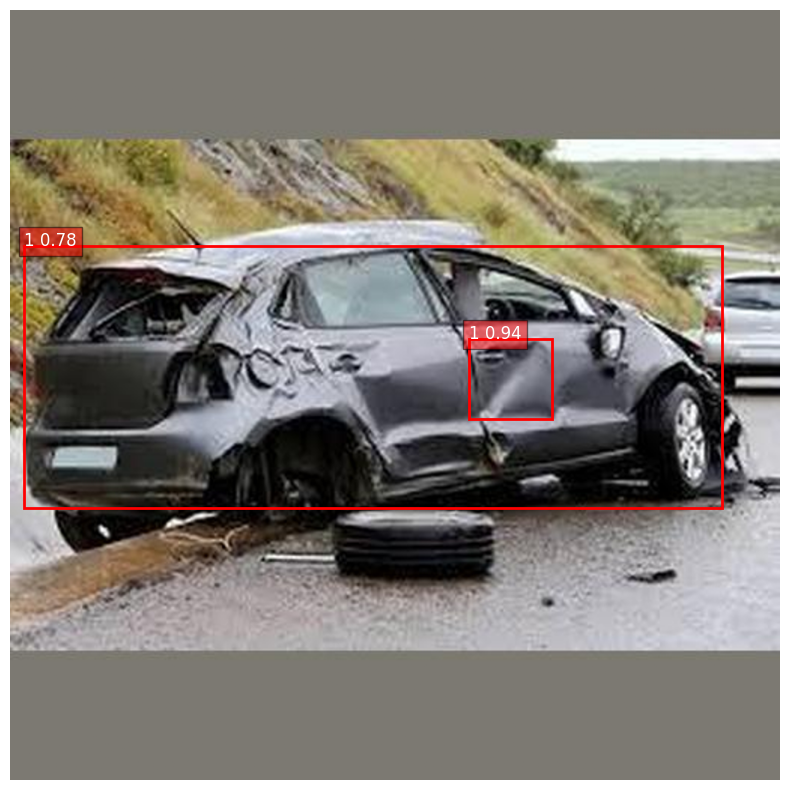

In [19]:
plot_detections(Image_Torch[0], TorchOutputs[0])